# Recommendation 03 — Diagnostica dei ranking MF / GTE / Popularity

**Scopo:** ispezionare alcuni utenti del benchmark `rs_coldstart_v1`, ricostruire le informazioni *effettivamente rivelate* ai modelli, verificare i film consigliati e analizzare il trattamento dei rating negativi **senza modificare i modelli, i ranking o gli split**.

Questo notebook legge i CSV **già generati** dai notebook `recommendation_01` e `recommendation_02` e il file originale `movies.csv`. **Per la parte principale NON esegue training MF, embedding GTE o chiamate a Qdrant/LLM.** I test controfattuali più costosi sono facoltativi e spenti per impostazione predefinita.

**Qualità delle inferenze:** un film senza rating MovieLens è *sconosciuto*, non un giudizio negativo. Le analisi sul test sono **post-hoc diagnostiche**, non vanno usate per selezionare iperparametri o modificare il modello osservando il test; le eventuali modifiche vanno selezionate su validation e confermate su un test non consultato / su nuove partizioni.

## 0 — Configurazione

Posiziona questo notebook in `<progetto>/notebooks/` accanto a `recommendation_02_baselines_mf_gte.ipynb`. Non spostare né modificare gli output esistenti.

**Non allegare i CSV privati agli LLM/agent workflow**: contengono il ground truth nascosto. Questo notebook usa la directory privata *solo* per l'analisi offline; eventuali tabelle esportate restano nella sottocartella privata.

In [1]:
from pathlib import Path
import ast
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None   # oppure Path('/.../progetto')
PROTOCOL_ID = "rs_coldstart_full"
DIAGNOSTIC_SPLIT = 'test'      # ispezione post-hoc, NON tuning
N_CASES = 8
SELECTION_SEED = 20261026
TOP_K = 10
POS_MIN = 4.0
NEG_MAX = 2.0
SAVE_PRIVATE_DIAGNOSTIC_CSV = True

# Controlli facoltativi su punteggi *reali* (nessun ricalcolo di embedding):
RUN_GTE_COUNTERFACTUAL = True  # richiede Qdrant raggiungibile, legge vettori esistenti
RUN_MF_REFIT = True            # riaddestra una copia MF per controfattuali; non scrive alcun modello
QDRANT_URL = 'http://localhost:6333'
QDRANT_COLLECTION = 'movies_d_full_enriched_v2_gte_multilingual_base_v1'
# QDRANT_MOVIE_ID_KEY = 'movieId'
QDRANT_MOVIE_ID_KEY = 'resource_id'
QDRANT_VECTOR_NAME = None


def find_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    current = Path.cwd().resolve()
    for root in [current, *list(current.parents)[:5]]:
        manifest = root/'datasets/processed/recommendation_protocol'/PROTOCOL_ID/'protocol_manifest.json'
        if manifest.is_file():
            return root
    raise FileNotFoundError('Non trovo protocol_manifest.json. Imposta PROJECT_ROOT_OVERRIDE.')

ROOT=find_root()
BASE=ROOT/'datasets/processed/recommendation_protocol'/PROTOCOL_ID
INPUTS=BASE/'inputs'
PRIVATE=BASE/'private_evaluation'
PRED=BASE/'predictions'
REPORT=BASE/'evaluations'/'baseline_mf_gte'
OUT=PRIVATE/'diagnostics_baselines'
RAW_MOVIES=ROOT/'datasets/raw/ml-latest-small/movies.csv'

candidate_source=[ROOT/'notebooks/recommendation_02_baselines_mf_gte.ipynb',
                  ROOT/'recommendation_02_baselines_mf_gte.ipynb',
                  *sorted((ROOT/'notebooks').glob('recommendation_02_baselines_mf_gte*.ipynb'))]
SOURCE_NOTEBOOK=next((x for x in candidate_source if x.exists()),None)
print('Root:',ROOT)
print('Ranking:',PRED/'rankings_baselines_test.csv')
print('Solo diagnostica; sorgente formule MF/GTE:', SOURCE_NOTEBOOK or '(non trovato: test unitari saltati)')

Root: /Users/danieleraveglia/Documents/uniMi/TESI/progetto
Ranking: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/predictions/rankings_baselines_test.csv
Solo diagnostica; sorgente formule MF/GTE: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/notebooks/recommendation_02_baselines_mf_gte.ipynb


## 1 — Caricamento: input pubblici e dati privati *soltanto per la valutazione*

Si usa il **ranking già salvato** (`rankings_baselines_test.csv`), non si ricrea un ordine in base ai rating nascosti. I titoli provengono dal MovieLens originale, le eventuali informazioni aggiuntive dai metadati TMDb già disponibili; non interroghiamo API esterne.

In [2]:
manifest=json.loads((BASE/'protocol_manifest.json').read_text(encoding='utf-8'))
config=json.loads((REPORT/'model_config.json').read_text(encoding='utf-8'))
if manifest.get('protocol_id')!=PROTOCOL_ID or config.get('protocol_id')!=PROTOCOL_ID:
    raise ValueError('Incoerenza protocol_id fra manifest e modello')
if int(manifest.get('fixed_holdout_size',0)) != 20 or int(manifest.get('profile_size',0)) != 10:
    raise ValueError('Protocollo diverso da 10/20')

items=pd.read_csv(INPUTS/'catalog_movie_ids.csv')
train=pd.read_csv(INPUTS/'train_ratings.csv')
levels=pd.read_csv(INPUTS/'scenario_levels.csv')
visible=pd.read_csv(INPUTS/'visible_interactions.csv')
scenarios=pd.read_csv(INPUTS/'scenarios.csv')
profile=pd.read_csv(PRIVATE/'private_profile.csv')
fixed=pd.read_csv(PRIVATE/'private_fixed_gt.csv')
extra=pd.read_csv(PRIVATE/'private_additional.csv')
ranking_path=PRED/'rankings_baselines_test.csv' if DIAGNOSTIC_SPLIT=='test' else PRED/'rankings_baselines_validation.csv'
if DIAGNOSTIC_SPLIT=='validation':
    raise ValueError('Questa versione diagnostica usa i modelli finali salvati sul TEST. '
                     'Su validation sono salvati diversi candidati di parametri: evitarne il confronto automatico.')
rankings=pd.read_csv(ranking_path)
movies=pd.read_csv(RAW_MOVIES)
if not {'movieId','title','genres'}.issubset(movies.columns):
    raise ValueError('movies.csv deve contenere movieId,title,genres')

for name,frame,required in [
    ('rankings',rankings,{'scenario_id','k','model','movieId','rank','score'}),
    ('profile',profile,{'scenario_id','movieId','rating','reveal_order'}),
    ('fixed',fixed,{'scenario_id','movieId','rating'}),
    ('extra',extra,{'scenario_id','movieId','rating'}),
    ('visible',visible,{'scenario_id','k','movieId','rating'}),
    ('levels',levels,{'scenario_id','k','userId','split'}),
]:
    missing=required-set(frame.columns)
    if missing:raise ValueError(f'{name}: mancano {sorted(missing)}')

for frame in (rankings,profile,fixed,extra,visible):
    frame['movieId']=frame['movieId'].astype('int64')
for frame in (rankings,visible,levels):frame['k']=frame['k'].astype(int)
rankings['rank']=rankings['rank'].astype(int)
ids=set(items.movieId.astype(int))
expected_models={'popularity','mf_explicit_foldin','gte_direct'}
assert set(rankings.model)==expected_models, f'Modelli inattesi: {sorted(rankings.model.unique())}'
assert set(rankings.movieId).issubset(ids)
assert levels[['scenario_id','k']].duplicated().sum()==0
assert rankings[['scenario_id','k','model','rank']].duplicated().sum()==0
assert profile.groupby('scenario_id').size().eq(10).all()
assert fixed.groupby('scenario_id').size().eq(20).all()
assert set(rankings.scenario_id).issubset(set(levels.loc[levels.split==DIAGNOSTIC_SPLIT,'scenario_id']))
assert not (set(scenarios.userId)&set(train.userId))

agg=train.groupby('movieId').rating.agg(train_n='size',train_mean='mean').reset_index()
info=movies[['movieId','title','genres']].merge(agg,on='movieId',how='left',validate='one_to_one')
info['train_n']=info.train_n.fillna(0).astype(int)
info_lookup=info.set_index('movieId')
print('Ranking:',len(rankings),'righe | utenti',rankings.scenario_id.str.extract(r'_u(\d+)_')[0].nunique(),
      '| scenari',rankings.scenario_id.nunique(),'| k',sorted(rankings.k.unique()))
print('Modelli:',sorted(rankings.model.unique()))
print('Configurazione:',{'mf_fold_reg':config.get('mf_fold_reg_selected'),
                         'gte_negative_alpha':config.get('gte_neg_alpha_selected'),
                         'gte_negative_only_alpha':config.get('gte_negative_only_alpha')})

Ranking: 22500 righe | utenti 50 | scenari 150 | k [np.int64(0), np.int64(1), np.int64(3), np.int64(5), np.int64(10)]
Modelli: ['gte_direct', 'mf_explicit_foldin', 'popularity']
Configurazione: {'mf_fold_reg': 1.0, 'gte_negative_alpha': 0.2, 'gte_negative_only_alpha': 0.35}


## 2 — Associa *offline* i rating reali ai film consigliati

Etichette: `A (20 fissi)`, `B extra` e `B profilo non rivelato` identificano rating nascosti differenti; `sconosciuto` significa **non giudicato**. Tutti i rating del profilo già rivelati devono essere assenti dalle raccomandazioni.

In [3]:
p=profile[['scenario_id','movieId','rating','reveal_order']].copy();p['truth_source']='profile_pool'
f=fixed[['scenario_id','movieId','rating']].copy();f['truth_source']='fixed_A';f['reveal_order']=np.nan
e=extra[['scenario_id','movieId','rating']].copy();e['truth_source']='additional';e['reveal_order']=np.nan
truth=pd.concat([p,f,e],ignore_index=True)
if truth[['scenario_id','movieId']].duplicated().any():raise ValueError('Rating duplicati fra profile / fixed / extra')

rank_size=rankings.groupby(['scenario_id','k','model']).agg(rows=('movieId','size'),unique_films=('movieId','nunique'),
                                                           unique_ranks=('rank','nunique'))
assert rank_size.rows.eq(TOP_K).all() and rank_size.unique_films.eq(TOP_K).all()
assert rank_size.unique_ranks.eq(TOP_K).all()
for _,g in rankings.groupby(['scenario_id','k','model']):
    assert np.array_equal(np.sort(g['rank'].values),np.arange(1,TOP_K+1))
    assert (g.sort_values('rank').score.diff().dropna() <= 1e-7).all()

ranked=rankings.merge(truth,on=['scenario_id','movieId'],how='left',validate='many_to_one')
ranked=ranked.merge(info,on='movieId',how='left',validate='many_to_one')
ranked=ranked.merge(levels[['scenario_id','k','userId','split']],on=['scenario_id','k'],how='left',validate='many_to_one')
assert ranked.title.notna().all() and ranked.userId.notna().all()
ranked['judgement_status']=np.select([
    ranked.rating.isna(),
    ranked.truth_source.eq('fixed_A'),
    ranked.truth_source.eq('additional'),
    ranked.truth_source.eq('profile_pool') & ranked.reveal_order.gt(ranked.k),
    ranked.truth_source.eq('profile_pool') & ranked.reveal_order.le(ranked.k),
],['sconosciuto','A (20 fissi)','B extra','B profilo non rivelato','ERRORE: rivelato'],default='VERIFICARE')
assert not ranked.judgement_status.str.startswith('ERRORE').any(), 'Il modello ha raccomandato film rivelati!'
assert not ranked.judgement_status.eq('VERIFICARE').any()
ranked['valutazione']=np.select([ranked.rating.ge(POS_MIN),ranked.rating.le(NEG_MAX),ranked.rating.notna()],
                               ['positivo','negativo','intermedio'], default='sconosciuto')
ranked['hit_A']=ranked.judgement_status.eq('A (20 fissi)')&ranked.rating.ge(POS_MIN)
ranked['hit_B']=ranked.rating.ge(POS_MIN)

# Confronto a k=0: stesso identico ranking, non un successo autonomo di GTE/MF.
zero=rankings.loc[rankings.k==0].sort_values(['scenario_id','model','rank'])
for sid,g in zero.groupby('scenario_id'):
    bas=g.loc[g.model=='popularity','movieId'].tolist()
    for _,sub in g.groupby('model'):
        assert sub.movieId.tolist()==bas, f'A k=0 ranking inatteso: {sid}'

n_unknown=ranked.groupby(['k','model']).agg(
    n_scenari=('scenario_id','nunique'),
    pos_A=('hit_A','mean'),
    pos_B=('hit_B','mean'),
    percent_unjudged=('judgement_status',lambda s: 100*(s=='sconosciuto').mean()),
    rating_train_medio_suggeriti=('train_n','mean'),
).reset_index()
display(n_unknown.round(3))
print('Verifiche ranking/anti-leakage OK. Il giudizio privato è stato associato DOPO il ranking.')

,k,model,n_scenari,pos_A,pos_B,percent_unjudged,rating_train_medio_suggeriti
0,0,gte_direct,150,0.052,0.272,65.200,156.600
1,0,mf_explicit_foldin,150,0.052,0.272,65.200,156.600
2,0,popularity,150,0.052,0.272,65.200,156.600
3,1,gte_direct,150,0.024,0.159,78.200,77.335
4,1,mf_explicit_foldin,150,0.018,0.069,91.267,53.239
5,1,popularity,150,0.053,0.269,65.467,156.930
6,3,gte_direct,150,0.022,0.100,85.333,42.269
7,3,mf_explicit_foldin,150,0.021,0.085,89.133,59.691
8,3,popularity,150,0.053,0.264,66.133,157.963
9,5,gte_direct,150,0.022,0.090,87.667,37.991


Verifiche ranking/anti-leakage OK. Il giudizio privato è stato associato DOPO il ranking.


## 3 — Diagnostica della personalizzazione (non tuning)

Controlliamo se MF/GTE tendono a raccomandare film con meno rating nel training e se i risultati differiscono tra profili con primo voto positivo, negativo o intermedio. I film senza voto rimangono sconosciuti; questa tabella non permette di dichiarare che siano raccomandazioni sbagliate.

,prima_valutazione,model,scenari,top10_pos_A,top10_pos_B,suggerimenti_sconosciuti_pct,training_rating_medi_film
0,intermedio,gte_direct,47,0.043,0.317,57.234,156.600
1,intermedio,mf_explicit_foldin,47,0.013,0.064,91.277,53.291
2,intermedio,popularity,47,0.043,0.317,57.234,156.600
3,negativo,gte_direct,14,0.043,0.300,61.429,161.350
4,negativo,mf_explicit_foldin,14,0.021,0.071,92.143,52.893
5,negativo,popularity,14,0.043,0.293,61.429,156.600
6,positivo,gte_direct,89,0.011,0.054,91.910,22.260
7,positivo,mf_explicit_foldin,89,0.020,0.072,91.124,53.266
8,positivo,popularity,89,0.060,0.240,70.449,157.156


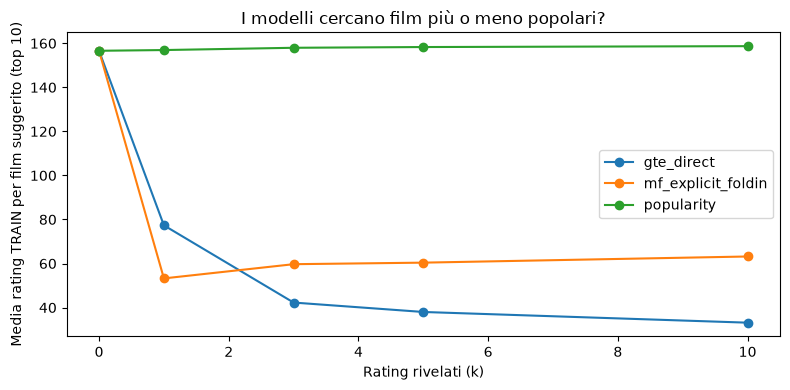

In [4]:
def first_type(sid):
    r=profile.loc[(profile.scenario_id==sid)&(profile.reveal_order==1),'rating'].iloc[0]
    return 'positivo' if r>=POS_MIN else ('negativo' if r<=NEG_MAX else 'intermedio')

first=pd.DataFrame({'scenario_id':sorted(ranked.scenario_id.unique())})
first['prima_valutazione']=first.scenario_id.map(first_type)
compare=ranked.merge(first,on='scenario_id',how='left')
summary=(compare.loc[compare.k==1]
    .groupby(['prima_valutazione','model'],as_index=False)
    .agg(scenari=('scenario_id','nunique'),top10_pos_A=('hit_A','mean'),
         top10_pos_B=('hit_B','mean'),
         suggerimenti_sconosciuti_pct=('judgement_status',lambda x:100*(x=='sconosciuto').mean()),
         training_rating_medi_film=('train_n','mean')))
display(summary.round(3))

plt.figure(figsize=(8,4))
for model,g in n_unknown.groupby('model'):
    plt.plot(g.k,g.rating_train_medio_suggeriti,marker='o',label=model)
plt.xlabel('Rating rivelati (k)');plt.ylabel('Media rating TRAIN per film suggerito (top 10)')
plt.title('I modelli cercano film più o meno popolari?')
plt.legend();plt.tight_layout();plt.show()

## 4 — Seleziona scenari interessanti senza modificarli

Campioniamo in modo **deterministico e descrittivo**: primo rating negativo / positivo / intermedio, profilo misto e profilo con pochi positivi. Sono esempi scelti per **tipo di input**, non per migliorare le metriche. Le repliche dello stesso utente non sono indipendenti: mostriamo preferibilmente utenti distinti.

Se vuoi esaminare un caso specifico, imposta `MANUAL_CASES` con coppie `(scenario_id,k)` presenti nei ranking.

In [5]:
MANUAL_CASES=[]  # ad es. [('test_u42_r0',3)]

case_candidates=[]
for sid, g in profile.groupby('scenario_id'):
    g=g.sort_values('reveal_order')
    uid=int(scenarios.loc[scenarios.scenario_id==sid,'userId'].iloc[0])
    rep=int(scenarios.loc[scenarios.scenario_id==sid,'rep'].iloc[0])
    if rep!=0:continue
    for k in (1,3,5,10):
        seq=g.head(k).rating.to_numpy(float)
        npos=int((seq>=POS_MIN).sum());nneg=int((seq<=NEG_MAX).sum());nmid=k-npos-nneg
        if k==1: label='primo_positivo' if npos else ('primo_negativo' if nneg else 'primo_intermedio')
        elif npos>0 and nneg>0:label='misto'
        elif npos==0:label='senza_positivi'
        elif nneg==0:label='senza_negativi'
        else:label='altro'
        case_candidates.append({'scenario_id':sid,'userId':uid,'k':k,'classe':label,
                                'n_pos':npos,'n_neg':nneg,'n_mid':nmid})
case_candidates=pd.DataFrame(case_candidates)
if MANUAL_CASES:
    chosen=case_candidates.merge(pd.DataFrame(MANUAL_CASES,columns=['scenario_id','k']),
                                 on=['scenario_id','k'],how='inner')
    if len(chosen)!=len(MANUAL_CASES):raise ValueError('MANUAL_CASES inesistenti nel protocollo')
else:
    rng=np.random.default_rng(SELECTION_SEED)
    priorities=[('primo_negativo',1),('primo_positivo',1),('primo_intermedio',1),
                ('misto',3),('misto',5),('senza_positivi',5),('senza_negativi',5),('misto',10),
                ('senza_negativi',10),('senza_positivi',10)]
    selected=[];used_users=set()
    for cls,k in priorities:
        candidates=case_candidates[(case_candidates.classe==cls)&(case_candidates.k==k)&
                                   (~case_candidates.userId.isin(used_users))]
        if candidates.empty:continue
        record=candidates.iloc[int(rng.integers(len(candidates)))].to_dict()
        selected.append(record);used_users.add(record['userId'])
        if len(selected)>=N_CASES:break
    chosen=pd.DataFrame(selected)
if chosen.empty:raise ValueError('Nessuno scenario diagnostico selezionato')
print('Scenari selezionati:',len(chosen),'| utenti distinti:',chosen.userId.nunique())
display(chosen[['scenario_id','userId','k','classe','n_pos','n_neg','n_mid']])

Scenari selezionati: 8 | utenti distinti: 8


,scenario_id,userId,k,classe,n_pos,n_neg,n_mid
0,validation_u264_r0,264,1,primo_negativo,0,1,0
1,validation_u405_r0,405,1,primo_positivo,1,0,0
2,test_u356_r0,356,1,primo_intermedio,0,0,1
3,validation_u287_r0,287,3,misto,2,1,0
4,test_u481_r0,481,5,misto,2,2,1
5,validation_u262_r0,262,5,senza_positivi,0,1,4
6,test_u222_r0,222,5,senza_negativi,1,0,4
7,test_u551_r0,551,10,misto,7,1,2


## 5 — Film rivelati e top 10 dei tre recommender

Per ogni scenario selezionato: `Input` contiene solo ciò che i modelli conoscevano. Nelle tabelle dei suggerimenti i `rating_reale` e `origine_rating` sono un'**annotazione a posteriori** accessibile solo al valutatore.

**Non confrontare gli score numerici tra algoritmi diversi:** le scale degli score MF/GTE/Popularity non coincidono.

In [6]:
def show_case(sid,k):
    uid=int(scenarios.loc[scenarios.scenario_id==sid,'userId'].iloc[0])
    display(Markdown(f'### Utente {uid} — scenario `{sid}` — k={k}'))
    observed=profile.loc[(profile.scenario_id==sid)&(profile.reveal_order<=k)]
    obs_show=observed.merge(info,on='movieId',how='left',validate='many_to_one')
    if len(obs_show):
        display(obs_show.sort_values('reveal_order')[['reveal_order','movieId','title','genres','rating']]
                .rename(columns={'rating':'rating_rivelato','reveal_order':'ordine'}))
    else:print('Nessun rating rivelato (k=0)')
    rows=ranked.loc[(ranked.scenario_id==sid)&(ranked.k==k)].sort_values(['model','rank'])
    for name, group in rows.groupby('model'):
        print('MODELLO:',name)
        cols=['rank','movieId','title','genres','score','train_n','rating','valutazione','judgement_status']
        shown=group[cols].rename(columns={'rating':'rating_reale','judgement_status':'origine_rating'})
        display(shown.round({'score':4}).reset_index(drop=True))
        print('Hit A:',int(group.hit_A.sum()),'| Hit B:',int(group.hit_B.sum()),
              '| Mai valutati:',int(group.rating.isna().sum()),'| Rating negativi noti:',
              int(group.valutazione.eq('negativo').sum()))

for item in chosen.itertuples(index=False):
    show_case(item.scenario_id,int(item.k))

### Utente 264 — scenario `validation_u264_r0` — k=1

,ordine,movieId,title,genres,rating_rivelato
0,1,3578,Gladiator (2000),Action|Adventure|Drama,2.0


### Utente 405 — scenario `validation_u405_r0` — k=1

,ordine,movieId,title,genres,rating_rivelato
0,1,7134,"Element of Crime, The (Forbrydelsens Element) ...",Drama|Thriller,4.0


### Utente 356 — scenario `test_u356_r0` — k=1

,ordine,movieId,title,genres,rating_rivelato
0,1,5989,Catch Me If You Can (2002),Crime|Drama,3.5


... (34 outputs left out)

,rank,movieId,title,genres,score,train_n,rating_reale,valutazione,origine_rating
0,1,246,Hoop Dreams (1994),Documentary,4.3878,25,NaN,sconosciuto,sconosciuto
1,2,898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,4.3628,22,NaN,sconosciuto,sconosciuto
2,3,1204,Lawrence of Arabia (1962),Adventure|Drama|War,4.3610,39,NaN,sconosciuto,sconosciuto
3,4,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.3194,261,4.0,positivo,B extra
4,5,1178,Paths of Glory (1957),Drama|War,4.3100,12,NaN,sconosciuto,sconosciuto
5,6,56782,There Will Be Blood (2007),Drama|Western,4.3090,27,NaN,sconosciuto,sconosciuto
6,7,1104,"Streetcar Named Desire, A (1951)",Drama,4.2811,17,NaN,sconosciuto,sconosciuto
7,8,3468,"Hustler, The (1961)",Drama,4.2768,17,NaN,sconosciuto,sconosciuto
8,9,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.2641,82,NaN,sconosciuto,sconosciuto
9,10,3275,"Boondock Saints, The (2000)",Action|Crime|Drama|Thriller,4.2581,34,NaN,sconosciuto,sconosciuto


Hit A: 0 | Hit B: 1 | Mai valutati: 9 | Rating negativi noti: 0
MODELLO: popularity


,rank,movieId,title,genres,score,train_n,rating_reale,valutazione,origine_rating
0,1,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.3737,261,4.0,positivo,B extra
1,2,527,Schindler's List (1993),Drama|War,4.2069,179,NaN,sconosciuto,sconosciuto
2,3,858,"Godfather, The (1972)",Crime|Drama,4.2002,163,NaN,sconosciuto,sconosciuto
3,4,1213,Goodfellas (1990),Crime|Drama,4.1918,103,NaN,sconosciuto,sconosciuto
4,5,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.1896,173,4.5,positivo,B extra
5,6,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.1800,83,NaN,sconosciuto,sconosciuto
6,7,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.1799,172,NaN,sconosciuto,sconosciuto
7,8,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.1759,108,NaN,sconosciuto,sconosciuto
8,9,2329,American History X (1998),Crime|Drama,4.1556,108,NaN,sconosciuto,sconosciuto
9,10,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.1497,203,3.5,intermedio,B extra


Hit A: 0 | Hit B: 2 | Mai valutati: 7 | Rating negativi noti: 0


## 6 — Cosa cambia quando arrivano nuovi rating?

Confrontiamo il top 10 **salvato** ai livelli successivi e riportiamo quanti nuovi positivi/negativi sono stati rivelati. Il cambiamento del ranking, da solo, **non dimostra** che la penalità negativa sia corretta: all'aumentare di `k` cambiano anche il profilo e i film esclusi, e con salvataggio della sola top 10 non vediamo gli score di tutti i candidati.

In [7]:
changes=[]
transitions=[(0,1),(1,3),(3,5),(5,10)]
for sid, g in profile.groupby('scenario_id'):
    g=g.sort_values('reveal_order')
    for before,after in transitions:
        newly=g.loc[g.reveal_order.gt(before)&g.reveal_order.le(after)]
        for model in sorted(expected_models):
            old=rankings.loc[(rankings.scenario_id==sid)&(rankings.k==before)&(rankings.model==model)]
            new=rankings.loc[(rankings.scenario_id==sid)&(rankings.k==after)&(rankings.model==model)]
            if len(old)!=TOP_K or len(new)!=TOP_K:continue
            s_old=set(old.movieId.astype(int));s_new=set(new.movieId.astype(int))
            revealed=set(newly.movieId.astype(int))
            # Gli item dell'old ranking rivelati devono essere rimossi, ma non sono un segnale di personalizzazione.
            real_change=len((s_old-revealed)-s_new)
            changes.append({'scenario_id':sid,'from_k':before,'to_k':after,'model':model,
                            'n_new_pos':int((newly.rating>=POS_MIN).sum()),
                            'n_new_neg':int((newly.rating<=NEG_MAX).sum()),
                            'n_new_mid':int(newly.rating.between(2.5,3.5).sum()),
                            'n_top10_exits_excluding_revealed':real_change,
                            'overlap_top10':len(s_old&s_new),
                            'n_revealed_previously_top10':len(s_old&revealed)})
changes=pd.DataFrame(changes)
# Concentrarsi sulla transizione 0 -> 1, che aggiunge una sola informazione.
changes['new_signal']=np.select([changes.n_new_neg.eq(1)&changes.n_new_pos.eq(0)&changes.n_new_mid.eq(0),
                                  changes.n_new_pos.eq(1)&changes.n_new_neg.eq(0)&changes.n_new_mid.eq(0),
                                  changes.n_new_mid.eq(1)&changes.n_new_neg.eq(0)&changes.n_new_pos.eq(0)],
                                 ['solo_negativo','solo_positivo','solo_intermedio'],default='multiplo/misto')
display(changes.loc[changes.from_k==0].groupby(['new_signal','model'],as_index=False).agg(
    n_scenari=('scenario_id','size'),
    top10_preservati=('overlap_top10','mean'),
    top10_uscite_non_dovute_a_filtri=('n_top10_exits_excluding_revealed','mean')
).round(2))
print('Con un rating solo negativo e k=1, GTE dovrebbe usare popularity penalizzata, non il centroide positivo.')

,new_signal,model,n_scenari,top10_preservati,top10_uscite_non_dovute_a_filtri
0,solo_intermedio,gte_direct,47,10.00,0.00
1,solo_intermedio,mf_explicit_foldin,47,1.00,9.00
2,solo_intermedio,popularity,47,10.00,0.00
3,solo_negativo,gte_direct,14,9.50,0.50
4,solo_negativo,mf_explicit_foldin,14,1.00,9.00
5,solo_negativo,popularity,14,10.00,0.00
6,solo_positivo,gte_direct,89,0.07,9.85
7,solo_positivo,mf_explicit_foldin,89,1.00,8.92
8,solo_positivo,popularity,89,9.92,0.00


Con un rating solo negativo e k=1, GTE dovrebbe usare popularity penalizzata, non il centroide positivo.


## 7 — Test numerici sul *codice effettivo* del notebook 02 (senza training reale)

Estraiamo dal file `.ipynb` esattamente la classe `ExplicitMF` e le funzioni `unit` / `gte_scores` con l'AST Python. **Non eseguiamo le altre celle**, quindi non si avvia il training e non viene interrogato Qdrant. Usiamo dati giocattolo controllati per verificare l'effetto dei rating positivi e negativi, compreso il caso GTE *negative-only*.

Questa verifica conferma la direzione matematica della penalizzazione implementata, **non** che i fattori appresi sui dati reali siano semanticamente accurati.

In [8]:
def extract_definition(notebook_path, function_name):
    notebook=json.loads(Path(notebook_path).read_text(encoding='utf-8'))
    for cell in notebook.get('cells',[]):
        if cell.get('cell_type')!='code':continue
        src=''.join(cell.get('source',[]))
        try:tree=ast.parse(src)
        except SyntaxError:continue
        for node in tree.body:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name==function_name:
                return compile(ast.Module(body=[node],type_ignores=[]),str(notebook_path),'exec')
    raise LookupError(f'Definizione {function_name} non trovata in {notebook_path}')

if SOURCE_NOTEBOOK is not None:
    env={'np':np,'pd':pd}
    for name in ('ExplicitMF','unit','gte_scores'):
        exec(extract_definition(SOURCE_NOTEBOOK,name),env)
    # MF con fattori fissati: controlla che rating < media faccia scendere i film simili.
    toy_mf=env['ExplicitMF']([101,102,103],rank=2,epochs=0,seed=123)
    toy_mf.mu=3.0
    toy_mf.item_bias=np.zeros(3)
    toy_mf.Q=np.asarray([[1.,0.],[.8,0.],[-.8,0.]])
    pos_mf=toy_mf.score(pd.DataFrame({'movieId':[101],'rating':[5.0]}),fold_reg=1.0)
    neg_mf=toy_mf.score(pd.DataFrame({'movieId':[101],'rating':[1.0]}),fold_reg=1.0)
    assert pos_mf[1]>pos_mf[2], 'MF: positivo non favorisce il film simile'
    assert neg_mf[1]<neg_mf[2], 'MF: negativo non penalizza il film simile'
    print('MF: OK — rating di 5 e 1 producono preferenze di ranking in direzioni opposte.')
    display(pd.DataFrame({'film':['ancora','simile','opposto'],
                          'con_rating_5':pos_mf,'con_rating_1':neg_mf}).round(4))

    # GTE con embedding fissi: 101 piace; 102 non piace; 103 è simile a 102; 104 è simile a 101.
    env['gte_vectors']=np.asarray([[1.,0.],[0.,1.],[0.,1.],[1.,0.]])
    env['idx_movie']={101:0,102:1,103:2,104:3}
    env['POS_MIN']=POS_MIN;env['NEG_MAX']=NEG_MAX
    env['GTE_NEG_ONLY_ALPHA']=float(config.get('gte_negative_only_alpha',.35))
    env['popularity_scores']=np.array([3.,3.,3.,3.])
    env['pop_z']=np.zeros(4)
    observed=pd.DataFrame({'movieId':[101,102],'rating':[5.0,1.0]})
    without_penalty=env['gte_scores'](observed,negative_alpha=0.0)
    with_penalty=env['gte_scores'](observed,negative_alpha=float(config.get('gte_neg_alpha_selected',.2)))
    assert np.isclose(without_penalty[2],without_penalty[1])
    assert with_penalty[2]<without_penalty[2], 'GTE: il negativo non penalizza film simili'
    assert np.isclose(with_penalty[3],without_penalty[3]), 'GTE: film ortogonale al negativo non dovrebbe essere penalizzato'
    neg_only=env['gte_scores'](pd.DataFrame({'movieId':[102],'rating':[1.0]}))
    assert neg_only[2]<neg_only[3], 'GTE: negative-only non penalizza i film simili'
    print('GTE: OK — in modalità positiva+negativa e solo-negativa la penalità è attiva.')
    display(pd.DataFrame({'film':['positivo 101','negativo 102','simile al negativo 103','simile al positivo 104'],
                          'alpha_0':without_penalty,'alpha_scelto':with_penalty,
                          'solo_negativo':neg_only}).round(4))
else:
    print('SKIP test codice: notebook 02 non trovato. I ranking rimangono analizzabili.')

MF: OK — rating di 5 e 1 producono preferenze di ranking in direzioni opposte.


,film,con_rating_5,con_rating_1
0,ancora,4.6667,1.3333
1,simile,4.6000,1.4000
2,opposto,4.0667,1.9333


GTE: OK — in modalità positiva+negativa e solo-negativa la penalità è attiva.


,film,alpha_0,alpha_scelto,solo_negativo
0,positivo 101,1.0,1.0,0.00
1,negativo 102,0.0,-0.2,-1.05
2,simile al negativo 103,0.0,-0.2,-1.05
3,simile al positivo 104,1.0,1.0,0.00


## 8 — Controfattuali reali opzionali (nessun cambio al benchmark)

Questo passaggio è **facoltativo e disabilitato**. Può essere utile per studiare *un singolo profilo reale* con almeno un negativo. Non aggiorna i ranking ufficiali e non esporta nuove metriche.

- **GTE:** legge vettori GTE già memorizzati su Qdrant e confronta lo stesso profilo con `alpha=0` e `alpha` scelto. Non ricalcola nessun embedding.
- **MF:** se abilitato, riaddestra una copia con gli stessi parametri e seed del notebook 02, esclusivamente per verificare la differenza nei punteggi quando viene aggiunto un rating negativo. È più costoso, ma non modifica gli artifact esistenti.

**Queste ispezioni non autorizzano tuning sul test.**

In [9]:
real_neg = []
for row in profile.groupby('scenario_id'):
    sid,grp=row
    grp=grp.sort_values('reveal_order')
    if not (grp.rating<=NEG_MAX).any():continue
    for k in (1,3,5,10):
        v=grp.head(k)
        if (v.rating<=NEG_MAX).any():
            real_neg.append((sid,k,len(v[v.rating>=POS_MIN]),len(v[v.rating<=NEG_MAX])))
            break
real_neg=sorted(real_neg,key=lambda x:(x[1],x[0]))
real_mixed=[]
for sid,grp in profile.groupby('scenario_id'):
    grp=grp.sort_values('reveal_order')
    for kk in (3,5,10):
        vv=grp.head(kk)
        if (vv.rating>=POS_MIN).any() and (vv.rating<=NEG_MAX).any():
            real_mixed.append((sid,kk));break
real_mixed=sorted(real_mixed,key=lambda x:(x[1],x[0]))
if real_neg:
    example_sid,example_k,_,_=real_neg[0]
    example_profile=profile[(profile.scenario_id==example_sid)&(profile.reveal_order<=example_k)]
    print('Caso negativo reale disponibile:',example_sid,'k',example_k)
else:
    example_profile=None
    print('Nessuno scenario con rating negativo rivelato')

if RUN_GTE_COUNTERFACTUAL:
    if SOURCE_NOTEBOOK is None or example_profile is None:raise RuntimeError('Sorgente notebook 02 o profilo negativo non trovato')
    from qdrant_client import QdrantClient
    client=QdrantClient(url=QDRANT_URL,timeout=60)
    ids_sorted=np.sort(items.movieId.astype(int).unique())
    found={};offset=None
    while True:
        points,offset=client.scroll(collection_name=QDRANT_COLLECTION,offset=offset,limit=256,
                                    with_vectors=True,with_payload=True)
        # print(points[1].payload)
        for pt in points:
            # print(pt.payload)
            mid=(pt.payload or {}).get(QDRANT_MOVIE_ID_KEY)
            if mid is None:
                print(QDRANT_MOVIE_ID_KEY)
                raise ValueError('movieId mancante in Qdrant: specificare QDRANT_MOVIE_ID_KEY')
            vv=pt.vector
            if isinstance(vv,dict):
                name=QDRANT_VECTOR_NAME or (next(iter(vv)) if len(vv)==1 else None)
                if name is None:raise ValueError('Vettori multipli: impostare QDRANT_VECTOR_NAME')
                vv=vv[name]
            found[int(mid)]=np.asarray(vv,dtype=float)
        if offset is None:break
    if not set(ids_sorted).issubset(found):raise ValueError('Collezione Qdrant non copre tutti i movieId')
    vv=np.stack([found[int(mid)] for mid in ids_sorted])
    vv=vv/np.linalg.norm(vv,axis=1,keepdims=True)
    global_mu=float(train.rating.mean())
    stats=train.groupby('movieId').rating.agg(['sum','count']).reindex(ids_sorted,fill_value=0)
    prior=float(config['popularity_prior'])
    real_pop=(stats['sum'].to_numpy(float)+prior*global_mu)/(stats['count'].to_numpy(float)+prior)
    real_pop_z=(real_pop-real_pop.mean())/max(real_pop.std(),1e-8)
    env_g={'np':np,'pd':pd,'gte_vectors':vv,'idx_movie':{int(mid):j for j,mid in enumerate(ids_sorted)},
           'POS_MIN':POS_MIN,'NEG_MAX':NEG_MAX,
           'GTE_NEG_ONLY_ALPHA':float(config.get('gte_negative_only_alpha',.35)),
           'popularity_scores':real_pop, 'pop_z':real_pop_z}
    for name in ('unit','gte_scores'):exec(extract_definition(SOURCE_NOTEBOOK,name),env_g)
    if real_mixed:
        sid_mixed,k_mixed=real_mixed[0]
        mixed_input=profile[(profile.scenario_id==sid_mixed)&
                            (profile.reveal_order<=k_mixed)][['movieId','rating']].copy()
        sc_off=env_g['gte_scores'](mixed_input,negative_alpha=0.)
        sc_on=env_g['gte_scores'](mixed_input,negative_alpha=float(config['gte_neg_alpha_selected']))
        result_cf=pd.DataFrame({'movieId':ids_sorted,'score_senza_negativi':sc_off,
                                'score_con_negativi':sc_on})
        result_cf['delta_negativo']=result_cf.score_con_negativi-result_cf.score_senza_negativi
        result_cf=result_cf.merge(info,on='movieId',how='left')
        print('GTE profilo misto:',sid_mixed,'k:',k_mixed, '| alpha=0 vs alpha scelto')
        display(result_cf.sort_values('delta_negativo').head(10)
                [['movieId','title','delta_negativo','score_senza_negativi','score_con_negativi']].round(4))
    else:
        print('Nessun profilo GTE misto trovato: impossibile confrontare negative_alpha.')
    if real_neg:
        only_sid,only_k,_,_=next((case for case in real_neg if case[2]==0),real_neg[0])
        only_input=profile[(profile.scenario_id==only_sid)&
                            (profile.reveal_order<=only_k)][['movieId','rating']].copy()
        if not (only_input.rating>=POS_MIN).any():
            sc_on=env_g['gte_scores'](only_input)
            env_g['GTE_NEG_ONLY_ALPHA']=0.0
            sc_off=env_g['gte_scores'](only_input)
            result_neg=pd.DataFrame({'movieId':ids_sorted,'con_penalita':sc_on,'senza_penalita':sc_off})
            result_neg['delta']=result_neg.con_penalita-result_neg.senza_penalita
            result_neg=result_neg.merge(info,on='movieId',how='left')
            print('GTE solo negativi:',only_sid,'k',only_k,
                  '| GTE_NEG_ONLY_ALPHA=0 vs valore in config')
            display(result_neg.sort_values('delta').head(10)
                    [['movieId','title','delta','con_penalita','senza_penalita']].round(4))
        else:
            print("Non c’è un profilo con solo negativi. Saltata verifica specifica.")
    print('I delta sono score, non differenze di NDCG, e precedono il filtro degli item rivelati.')

if RUN_MF_REFIT:
    if SOURCE_NOTEBOOK is None or example_profile is None:raise RuntimeError('Sorgente notebook 02 o profilo negativo non trovato')
    env_m={'np':np,'pd':pd}
    exec(extract_definition(SOURCE_NOTEBOOK,'ExplicitMF'),env_m)
    mf_clone=env_m['ExplicitMF'](np.sort(items.movieId.unique()),
        rank=int(config['mf_rank']),epochs=int(config['mf_epochs']),lr=float(config['mf_lr']),
        reg=float(config['mf_reg']),seed=int(config['seed'])).fit(train)
    full=example_profile[['movieId','rating']].copy()
    without=full.loc[full.rating>NEG_MAX].copy()
    sc_wo=mf_clone.score(without,fold_reg=float(config['mf_fold_reg_selected']))
    sc_w=mf_clone.score(full,fold_reg=float(config['mf_fold_reg_selected']))
    result_m=pd.DataFrame({'movieId':np.sort(items.movieId.unique()),'score_senza_negativi':sc_wo,
                           'score_con_negativi':sc_w})
    result_m['delta_negativo']=result_m.score_con_negativi-result_m.score_senza_negativi
    result_m=result_m.merge(info,on='movieId',how='left')
    display(result_m.sort_values('delta_negativo').head(10)
            [['movieId','title','delta_negativo','score_senza_negativi','score_con_negativi']].round(4))

if not RUN_GTE_COUNTERFACTUAL and not RUN_MF_REFIT:
    print('Controfattuali reali non eseguiti (opzionali): i ranking ufficiali sono invariati.')

Caso negativo reale disponibile: test_u110_r0 k 1
GTE profilo misto: test_u110_r0 k: 3 | alpha=0 vs alpha scelto


,movieId,title,delta_negativo,score_senza_negativi,score_con_negativi
193,227,Drop Zone (1994),-0.2000,0.7604,0.5604
1171,1552,Con Air (1997),-0.1766,0.7598,0.5832
400,459,"Getaway, The (1994)",-0.1759,0.7656,0.5896
1325,1792,U.S. Marshals (1998),-0.1753,0.7575,0.5822
431,494,Executive Decision (1996),-0.1749,0.7169,0.5420
3219,4351,Point Break (1991),-0.1743,0.7821,0.6078
480,548,Terminal Velocity (1994),-0.1740,0.7523,0.5783
8205,105653,Escape Plan (2013),-0.1737,0.7863,0.6125
4461,6595,S.W.A.T. (2003),-0.1734,0.7843,0.6109
1053,1370,Die Hard 2 (1990),-0.1732,0.7618,0.5886


GTE solo negativi: test_u110_r0 k 1 | GTE_NEG_ONLY_ALPHA=0 vs valore in config


,movieId,title,delta,con_penalita,senza_penalita
193,227,Drop Zone (1994),-1.0500,-2.3099,-1.2599
1171,1552,Con Air (1997),-0.9269,-2.8039,-1.8770
400,459,"Getaway, The (1994)",-0.9236,-2.7049,-1.7813
1325,1792,U.S. Marshals (1998),-0.9204,-1.9122,-0.9919
431,494,Executive Decision (1996),-0.9182,-1.1956,-0.2775
3219,4351,Point Break (1991),-0.9151,-1.2544,-0.3393
480,548,Terminal Velocity (1994),-0.9136,-1.5513,-0.6376
8205,105653,Escape Plan (2013),-0.9121,-0.0956,0.8165
4461,6595,S.W.A.T. (2003),-0.9104,-1.2414,-0.3310
1053,1370,Die Hard 2 (1990),-0.9093,-1.2046,-0.2953


I delta sono score, non differenze di NDCG, e precedono il filtro degli item rivelati.
MF epoch 1/18: train RMSE 0.9039
MF epoch 5/18: train RMSE 0.8486
MF epoch 10/18: train RMSE 0.8233
MF epoch 15/18: train RMSE 0.8031
MF epoch 18/18: train RMSE 0.7882


,movieId,title,delta_negativo,score_senza_negativi,score_con_negativi
193,227,Drop Zone (1994),-1.5845,2.9716,1.3871
2252,2990,Licence to Kill (1989),-1.5804,3.6136,2.0331
546,648,Mission: Impossible (1996),-1.5792,3.4583,1.8791
1164,1544,"Lost World: Jurassic Park, The (1997)",-1.5788,2.9393,1.3605
2113,2807,Universal Soldier: The Return (1999),-1.5763,3.1702,1.5939
3405,4638,Jurassic Park III (2001),-1.5758,2.9879,1.4121
806,1055,Shadow Conspiracy (1997),-1.5757,3.0584,1.4827
6259,47937,Severance (2006),-1.5755,3.3943,1.8188
839,1101,Top Gun (1986),-1.5753,3.3964,1.8212
655,848,"Spitfire Grill, The (1996)",-1.5752,3.3548,1.7796


## 9 — Salvataggio diagnostico privato e interpretazione

Tutte le tabelle di raccomandazioni annotate con i rating reali contengono **etichette private**. Vengono salvate in `private_evaluation/diagnostics_baselines/`, non in `inputs/` o `predictions/`.

**Come interpretare i risultati:**
- Se Popularity restituisce sistematicamente film con molte interazioni train, mentre GTE/MF preferiscono film poco valutati, la maggiore quantità di *judged* potrebbe spiegare parte del divario di NDCG.
- Se aggiungere un rating negativo cambia il ranking GTE come atteso nel test unitario ma non migliora NDCG, la formula è attiva, non necessariamente utile.
- Se alcuni film GTE/MF sono plausibili pur senza rating dell'utente, **non** sono falsi positivi osservati.
- Se un modello inserisce film che l'utente ha valutato ≤2, è un errore concreto su quel caso (nonostante la media generale possa rimanere buona).

**Passo successivo, solo dopo aver visto gli esempi:** eventuali modifiche a GTE+Popularity o alla regolarizzazione MF da valutare sulla sola **validation** e, per un confronto confermativo pulito, su una futura partizione test non usata per queste diagnosi.

In [10]:
if SAVE_PRIVATE_DIAGNOSTIC_CSV:
    OUT.mkdir(parents=True,exist_ok=True)
    ranked.to_csv(OUT/'top10_annotated_private.csv',index=False)
    summary.to_csv(OUT/'ranking_first_rating_diagnostics.csv',index=False)
    changes.to_csv(OUT/'ranking_transitions.csv',index=False)
    chosen.to_csv(OUT/'chosen_scenarios.csv',index=False)
    run_manifest={'source_ranking':str(ranking_path.relative_to(ROOT)),
                  'source_protocol':PROTOCOL_ID,'selected_scenarios':len(chosen),
                  'retrain_MF':RUN_MF_REFIT,'loaded_Qdrant':RUN_GTE_COUNTERFACTUAL,
                  'note':'POST-HOC DIAGNOSTICA. Label privati: non utilizzare in training o tuning sul test.'}
    (OUT/'diagnostics_manifest.json').write_text(json.dumps(run_manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Tabelle diagnostiche private:',OUT)
else:
    print('Nessun CSV privato salvato')

Tabelle diagnostiche private: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_protocol/rs_coldstart_full/private_evaluation/diagnostics_baselines
